전체 샘플 구성 -> 0번 클래스: 985개, 1번 클래스(소수): 15개
--- 테스트 데이터셋 기준 AUROC: 0.7980 ---


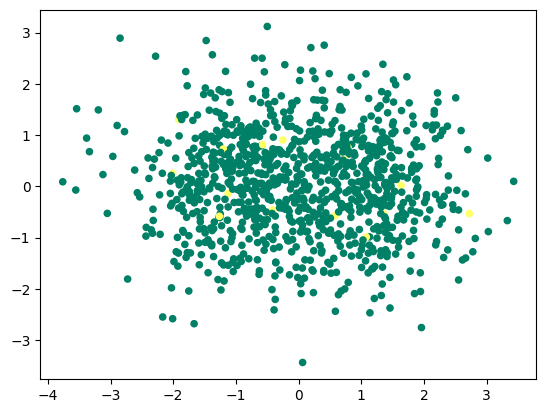

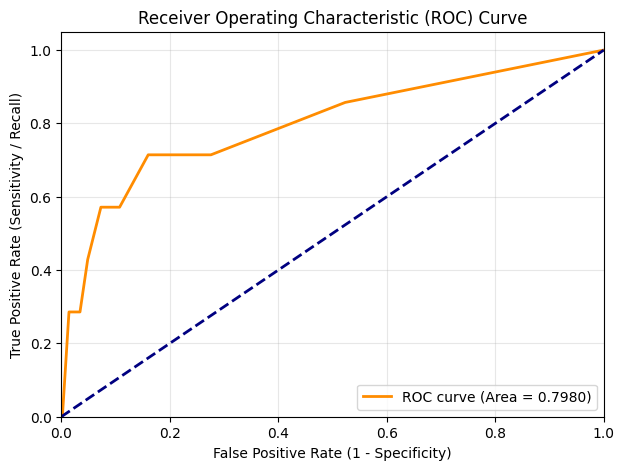

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score

# 1. 가상 데이터셋 생성 (소수 클래스 비율을 3%로 설정)
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=1000, n_classes=2, weights=[0.99, 0.01],
 random_state=1)
plt.scatter(X[:, 0], X[:, 1], c=y, s=20, cmap='summer')


print(f"전체 샘플 구성 -> 0번 클래스: {np.bincount(y)[0]}개, 1번 클래스(소수): {np.bincount(y)[1]}개")

# 2. 학습 데이터와 테스트 데이터 분리 (층화 추출 적용)
# stratify=y를 사용해야 분할 후에도 소수 클래스의 비율(3%)이 유지됩니다.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, stratify=y, random_state=42
)

# 3. 예측 모델 정의 및 학습 (Random Forest 사용)
# 불균형 데이터셋이므로 class_weight='balanced'를 주어 모델이 소수 클래스에 방점을 두게 합니다.
model = RandomForestClassifier(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

# 4. 소수 클래스(1)에 대한 예측 확률 추출
# AUROC를 계산할 때는 예측 라벨(0 또는 1)이 아니라 양성 클래스일 '확률'이 필요합니다.
y_pred_proba = model.predict_proba(X_test)[:, 1]

# 5. AUROC 계산
auroc = roc_auc_score(y_test, y_pred_proba)
print(f"--- 테스트 데이터셋 기준 AUROC: {auroc:.4f} ---")

# 6. ROC 커브 시각화
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (Area = {auroc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # 무작위 예측 기준선
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# Initialize lists to store TN, FP, FN, TP
tn_list = []
fp_list = []
fn_list = []
tp_list = []

for t in thresholds:
    # Predict binary labels for the current threshold
    y_pred_at_threshold = (y_pred_proba >= t).astype(int)

    # Calculate confusion matrix for the current threshold
    # Ensure confusion_matrix returns (tn, fp, fn, tp) in the correct order for binary classification
    cm = confusion_matrix(y_test, y_pred_at_threshold)
    tn, fp, fn, tp = cm.ravel() # Flatten the 2x2 matrix into 4 values

    tn_list.append(tn)
    fp_list.append(fp)
    fn_list.append(fn)
    tp_list.append(tp)

# Create a DataFrame for thresholds, TPR, FPR, and the new counts
threshold_df = pd.DataFrame({
    'Threshold': thresholds,
    'TPR (Recall)': tpr,
    'FPR': fpr,
    'TN': tn_list,
    'FP': fp_list,
    'FN': fn_list,
    'TP': tp_list
})

# Display the DataFrame
threshold_df

,Threshold,TPR (Recall),FPR,TN,FP,FN,TP
0,inf,0.000000,0.000000,493,0,7,0
1,0.14,0.000000,0.002028,492,1,7,0
2,0.11,0.285714,0.014199,486,7,5,2
3,0.09,0.285714,0.022312,482,11,5,2
4,0.07,0.285714,0.034483,476,17,5,2
5,0.06,0.428571,0.048682,469,24,4,3
6,0.05,0.571429,0.073022,457,36,3,4
7,0.04,0.571429,0.107505,440,53,3,4
8,0.03,0.714286,0.160243,414,79,2,5
9,0.02,0.714286,0.275862,357,136,2,5


In [ ]:
threshold_df.to_excel('threshold_df.xlsx', index=False)

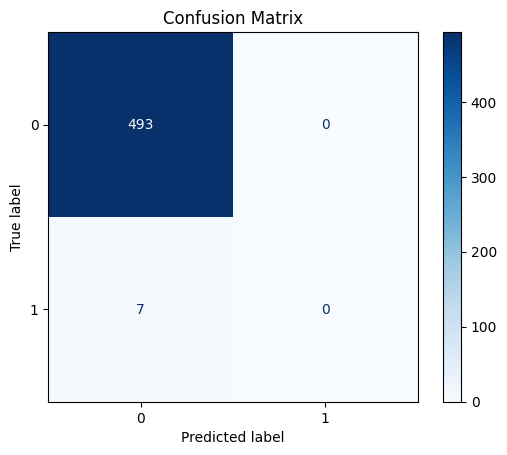

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 예측 라벨 추출 (클래스 0 또는 1)
y_pred = model.predict(X_test)

# Confusion Matrix 계산
cm = confusion_matrix(y_test, y_pred)

# Confusion Matrix 시각화
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Classification Report 출력
print(classification_report(y_test, y_pred))

NameError: name 'y_pred' is not defined

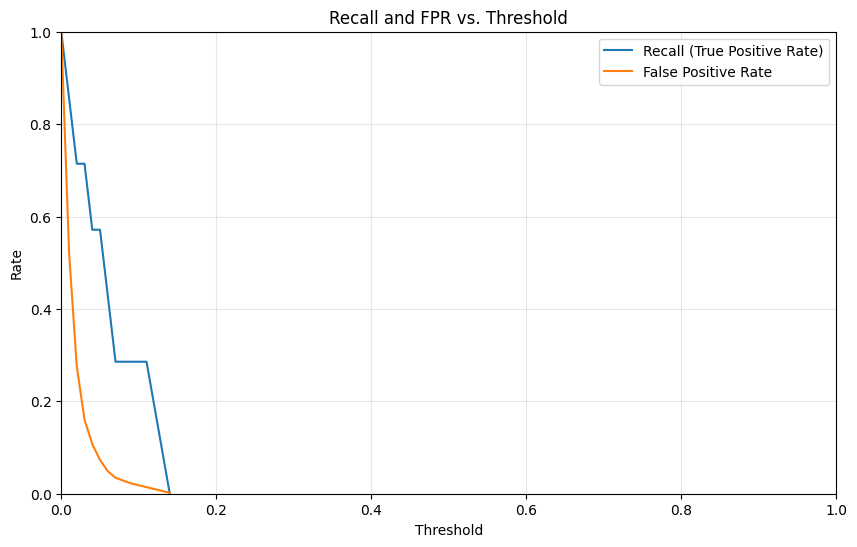

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(thresholds, tpr, label='Recall (True Positive Rate)')
plt.plot(thresholds, fpr, label='False Positive Rate')
plt.xlabel('Threshold')
plt.ylabel('Rate')
plt.title('Recall and FPR vs. Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.show()

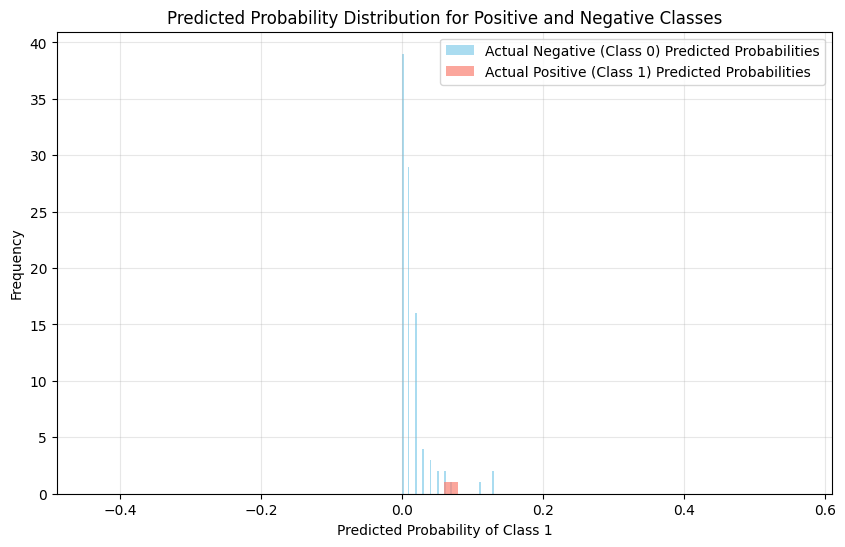

In [ ]:
plt.figure(figsize=(10, 6))

# 실제 Negative 클래스 (y_test=0)에 대한 예측 확률 분포
plt.hist(y_pred_proba[y_test == 0], bins=50, alpha=0.7, label='Actual Negative (Class 0) Predicted Probabilities', color='skyblue')

# 실제 Positive 클래스 (y_test=1)에 대한 예측 확률 분포
plt.hist(y_pred_proba[y_test == 1], bins=50, alpha=0.7, label='Actual Positive (Class 1) Predicted Probabilities', color='salmon')

plt.title('Predicted Probability Distribution for Positive and Negative Classes')
plt.xlabel('Predicted Probability of Class 1')
plt.ylabel('Frequency')
plt.legend()
plt.grid(alpha=0.3)
plt.show()